# Sub-unit hazard from nested reports, with a spatial field

Notebook 05 recovers a rate that is a known function of covariates from events reported at ADM2, ADM1 or ADM0. There the fitted map follows from two slopes, so it cannot show reporting losing spatial detail. This notebook adds a spatial field the covariates do not explain, at a scale near the size of an ADM2 unit, and asks how much of it each resolution of report can recover.

The likelihood is the one from 05. If an event's reporting level does not depend on where inside its country it fell, the events reported at unit $A$ are a Poisson process thinned to $A$, and

$$\log L = \sum_{A} n_A \log \Lambda_A - \sum_i \lambda_i, \qquad \Lambda_A = \sum_{i \in A} \lambda_i,$$

where $i$ runs over the atoms of the lattice and $A$ over every unit at every level. The reporting probabilities factor out as constants.

In [25]:
import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import shapely

from nested_plotting import (
    LATTICE_EXTENT,
    POSTERIOR_COLOR,
    RATE_FLOOR,
    TRUTH_COLOR,
    draw_borders,
    draw_stack,
    floored_log10,
    plot_atoms,
    plot_fields,
    spread_over_units,
)

from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, FIELD_SEED, EVENT_SEED, REPORTING_SEED = SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4

## The geography

A square lattice of atoms, grouped into ADM2 units, ADM2 into ADM1 and ADM1 into ADM0. Each level is a partition of the one below it, so an atom has exactly one ancestor at every level. Atoms are equal in area, which keeps the base measure out of the way.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}

In [4]:
atoms_per_unit = {level: np.bincount(unit_of_atom[level]) for level in LEVELS}

pd.DataFrame(
    {
        "units": {level: len(counts) for level, counts in atoms_per_unit.items()},
        "atoms per unit, smallest": {level: counts.min() for level, counts in atoms_per_unit.items()},
        "atoms per unit, median": {level: np.median(counts) for level, counts in atoms_per_unit.items()},
        "atoms per unit, largest": {level: counts.max() for level, counts in atoms_per_unit.items()},
    }
)

,units,"atoms per unit, smallest","atoms per unit, median","atoms per unit, largest"
ADM2,60,8,15.00,27
ADM1,12,42,70.00,105
ADM0,3,225,257.00,418


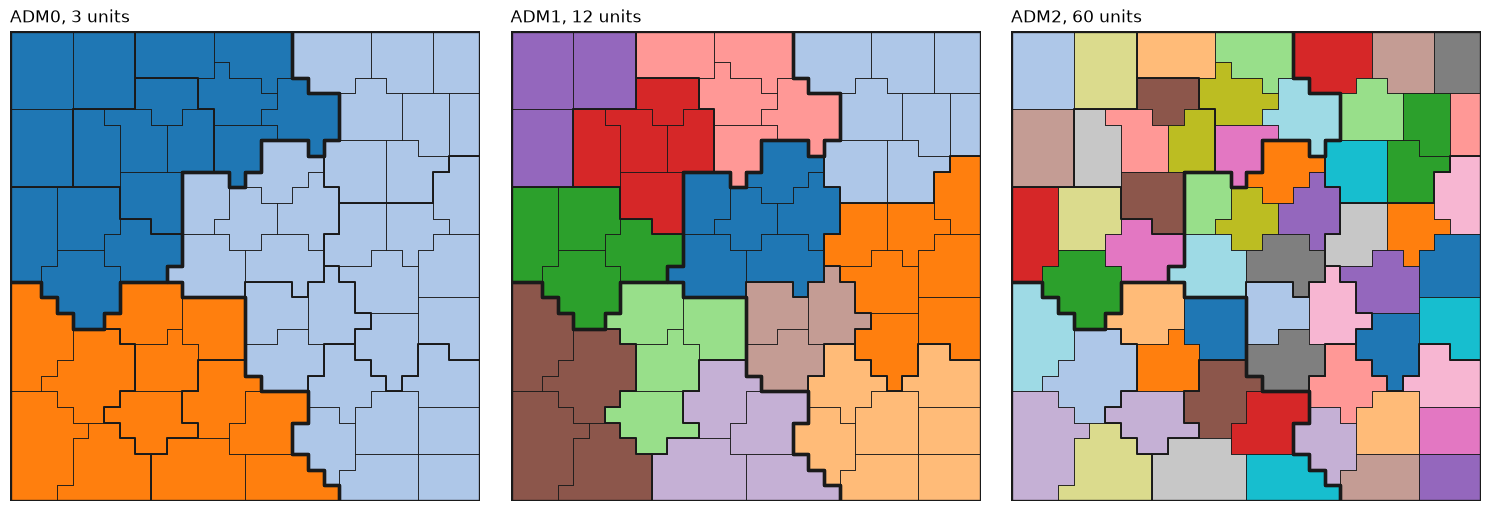

In [5]:
color_rng = np.random.default_rng(COLOR_SEED)

figure, axes = plt.subplots(1, len(LEVELS), figsize=(15, 5))

for axis, level in zip(axes, reversed(LEVELS), strict=True):
    count = unit_of_atom[level].max() + 1
    palette = plt.get_cmap("tab20")(color_rng.permutation(count) % 20)
    axis.imshow(palette[unit_of_atom[level]].reshape(GRID_SIDE, GRID_SIDE, 4),
                origin="lower",
                extent=LATTICE_EXTENT)
    draw_borders(axis, borders, color="0.1")

    axis.set_axis_off()
    axis.set_title(f"{level}, {count} units", loc="left")

plt.show()

Every unit is compact and every level nests in the one above. A median ADM2 holds 15 atoms and a median ADM0 holds 257, so a country-level report spreads an event over about 17 times as many atoms as an ADM2 report.

## The truth

Two covariates, distance to a river and elevation, both smooth in space and both varying inside every unit, plus a spatial field the covariates do not explain. The field is a draw from a Matern 3/2 Gaussian process over the atom coordinates, with a lengthscale near the size of an ADM2 unit, so its structure sits at a scale ADM2 reports can resolve and ADM1 and ADM0 reports average away. The log rate is the sum of the linear covariate term and the field, with the intercept solved so the record carries 150 events, about 50 per country. That is the range EM-DAT geocodes to admin units in Southeast Asia, from 9 events in Timor-Leste and 26 in Laos to 387 in the Philippines. The share of each term's variance that lies inside units at each level is the part a report at that level cannot see.

In [6]:
TARGET_EVENTS = 150
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")
TRUE_FIELD_AMPLITUDE = 0.7
TRUE_FIELD_LENGTHSCALE = 0.12
FIELD_JITTER = 1e-8


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


def matern32(points, *, amplitude, lengthscale):
    """The Matern 3/2 covariance between every pair of ``points``."""
    scaled = np.sqrt(3.0) * np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)) / lengthscale

    return amplitude**2 * (1.0 + scaled) * np.exp(-scaled)


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

field_rng = np.random.default_rng(FIELD_SEED)
field_covariance = matern32(atom_centroids, amplitude=TRUE_FIELD_AMPLITUDE, lengthscale=TRUE_FIELD_LENGTHSCALE)
field_covariance[np.diag_indices(n_atoms)] += FIELD_JITTER
true_field = np.linalg.cholesky(field_covariance) @ field_rng.standard_normal(n_atoms)
true_field -= true_field.mean()

linear_part = covariates @ TRUE_SLOPES
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS) - np.log(np.exp(linear_part + true_field).sum()))
true_log_rate = TRUE_INTERCEPT + linear_part + true_field
true_rate = np.exp(true_log_rate)

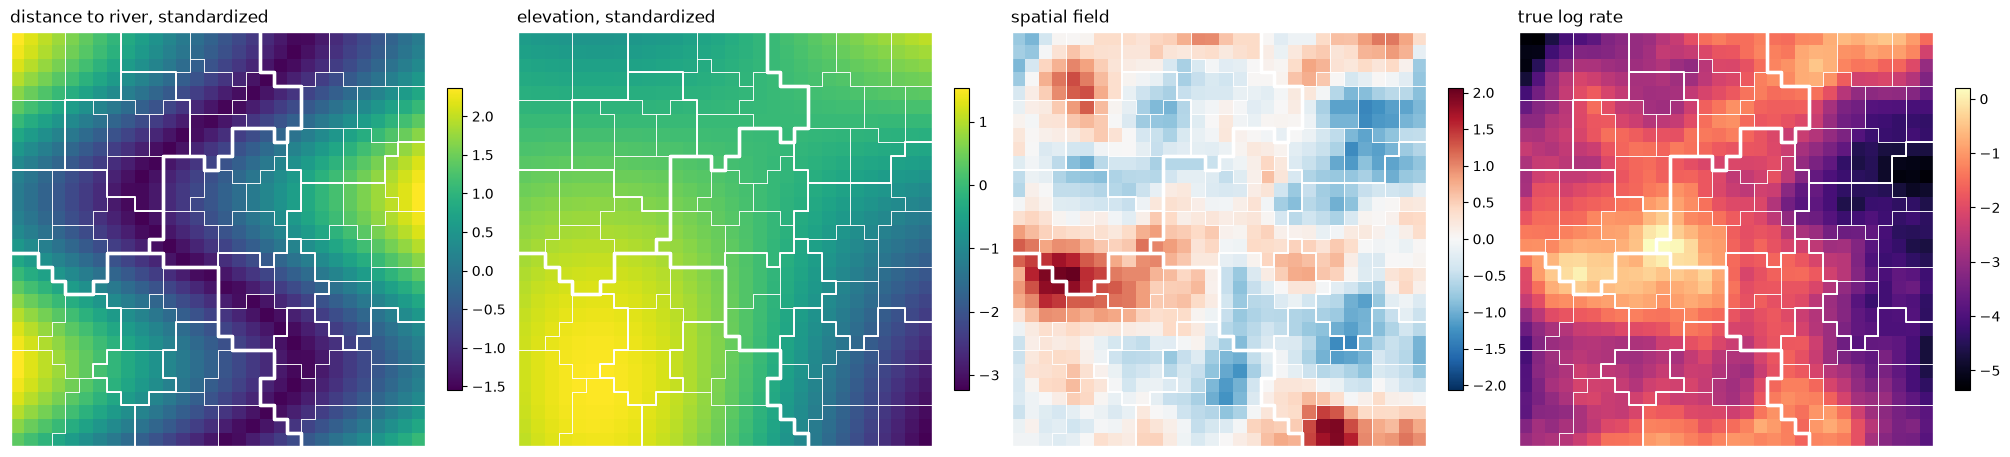

In [7]:
components = {**dict(zip(COVARIATE_NAMES, covariates.T, strict=True)), "spatial field": true_field}
field_limit = np.abs(true_field).max()

figure, axes = plt.subplots(1, 4, figsize=(20, 4.6))

for axis, (name, values) in zip(axes[:3], components.items(), strict=True):
    is_field = name == "spatial field"
    drawn = plot_atoms(axis,
                       values,
                       borders,
                       title=name if is_field else f"{name}, standardized",
                       cmap="RdBu_r" if is_field else "viridis",
                       vmin=-field_limit if is_field else None,
                       vmax=field_limit if is_field else None)
    figure.colorbar(drawn, ax=axis, shrink=0.7)

drawn = plot_atoms(axes[3], true_log_rate, borders, title="true log rate")
figure.colorbar(drawn, ax=axes[3], shrink=0.7)

plt.show()

In [8]:
def within_share(values, units):
    """Share of the variance of ``values`` that lies inside units, invisible to a report at that level."""
    unit_means = np.bincount(units, weights=values) / np.bincount(units)

    return float(((values - unit_means[units]) ** 2).sum() / ((values - values.mean()) ** 2).sum())


pd.DataFrame(
    {
        level: {name: within_share(values, unit_of_atom[level]) for name, values in components.items()}
        for level in LEVELS
    }
).rename_axis("variance inside units").round(3)

,ADM2,ADM1,ADM0
variance inside units,,,
distance to river,0.10,0.44,0.96
elevation,0.03,0.17,0.57
spatial field,0.34,0.84,0.96


The field keeps 34% of its variance inside ADM2 units, 84% inside ADM1 units and 96% inside ADM0 units. Its lengthscale is near the size of an ADM2, so an ADM2 record still sees two thirds of the field as contrast between units, and an ADM1 record sees a sixth. The covariates are those of 05: distance to river keeps 44% of its variance inside ADM1 units and elevation 17%, so both still vary between ADM1 units where the field mostly does not.

## Events and how they are reported

Events are drawn once, at the atoms. Each regime then reports the same events differently, so any difference between fits is the price of the reporting and nothing else. The atom regime is the oracle: every event located exactly. In the mixed regime each event draws its level from one set of shares everywhere. In the per-country regime each country has its own habit: one reports mostly at ADM2, one mostly at ADM1, and one only as a whole country. In both, the level is drawn independently of where inside its country the event fell, which is the condition under which the thinned likelihood is exact.

Every unit at every level becomes one row of a single operator, with atoms as a fourth level. A record is then a count per row, and a regime is a choice of which rows its events land in.

In [9]:
ALL_LEVELS = ("atom", *LEVELS)

unit_of_atom["atom"] = np.arange(n_atoms)
n_units = {level: int(unit_of_atom[level].max()) + 1 for level in ALL_LEVELS}
first_row = dict(zip(ALL_LEVELS, np.cumsum([0, *(n_units[level] for level in ALL_LEVELS[:-1])]), strict=True))
rows_of = {level: slice(first_row[level], first_row[level] + n_units[level]) for level in ALL_LEVELS}

reporting = Aggregation(units=tuple(f"{level} {unit}" for level in ALL_LEVELS for unit in range(n_units[level])),
                        rows=np.concatenate([first_row[level] + unit_of_atom[level] for level in ALL_LEVELS]),
                        columns=np.tile(np.arange(n_atoms), len(ALL_LEVELS)),
                        weights=np.ones(n_atoms * len(ALL_LEVELS)),
                        n_cells=n_atoms)


def country_of_units(level):
    """The ADM0 each unit at ``level`` lies in."""
    countries = np.empty(n_units[level], dtype=int)
    countries[unit_of_atom[level]] = unit_of_atom["ADM0"]

    return countries


country_of_row = np.concatenate([country_of_units(level) for level in ALL_LEVELS])
level_of_row = np.repeat(np.arange(len(ALL_LEVELS)), [n_units[level] for level in ALL_LEVELS])


def reports_by_country(counts):
    """Events reported at each level in each country, shape ``(country, level)``."""
    table = np.zeros((N_ADM0, len(ALL_LEVELS)))
    np.add.at(table, (country_of_row, level_of_row), counts)

    return table

In [10]:
MIXED_SHARES = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.3}
COUNTRY_SHARES = ({"ADM2": 0.8, "ADM1": 0.2}, {"ADM1": 0.8, "ADM0": 0.2}, {"ADM0": 1.0})

event_rng = np.random.default_rng(EVENT_SEED)
event_atoms = np.repeat(np.arange(n_atoms), event_rng.poisson(true_rate))
n_events = len(event_atoms)

reporting_rng = np.random.default_rng(REPORTING_SEED)


def record(levels):
    """The count reported at each row of ``reporting``, given the level each event is reported at."""
    reported_rows = [
        first_row[level] + unit_of_atom[level][atom] for atom, level in zip(event_atoms, levels, strict=True)
    ]

    return np.bincount(reported_rows, minlength=reporting.n_units)


def country_level(country):
    """One reporting level drawn from ``country``'s own shares."""
    shares = COUNTRY_SHARES[country]

    return reporting_rng.choice(list(shares), p=list(shares.values()))


regimes = {level: record([level] * n_events) for level in ALL_LEVELS}
regimes["mixed"] = record(reporting_rng.choice(list(MIXED_SHARES),
                                               size=n_events,
                                               p=list(MIXED_SHARES.values())))
regimes["by country"] = record([country_level(country) for country in unit_of_atom["ADM0"][event_atoms]])

pd.DataFrame(
    {regime: {level: counts[rows_of[level]].sum() for level in ALL_LEVELS} for regime, counts in regimes.items()}
).rename_axis("events reported at")

,atom,ADM2,ADM1,ADM0,mixed,by country
events reported at,,,,,,
atom,163,0,0,0,0,0
ADM2,0,163,0,0,44,52
ADM1,0,0,163,0,67,49
ADM0,0,0,0,163,52,62


In [11]:
pd.DataFrame(reports_by_country(regimes["by country"]).astype(int),
             index=pd.Index([f"ADM0 {country}" for country in range(N_ADM0)], name="by country"),
             columns=ALL_LEVELS)

,atom,ADM2,ADM1,ADM0
by country,,,,
ADM0 0,0,52,8,0
ADM0 1,0,0,41,15
ADM0 2,0,0,0,47


The same 163 events appear in every column. The per-country record keeps 52 events at ADM2, all of them in ADM0 0, and ADM0 2 reports only its own total of 47.

## The model, fitted under each regime

The rate is the truth's own form: log-linear in the covariates plus a latent Matern 3/2 field over the atom coordinates, with its amplitude and lengthscale learned. The field is a Hilbert-space approximation (Riutort-Mayol et al. 2022, [doi:10.1007/s11222-022-10167-2](https://doi.org/10.1007/s11222-022-10167-2)): a fixed set of Laplacian eigenfunctions on a box around the lattice, weighted by the kernel's spectral density. The basis is sized by the paper's rule for Matern 3/2 at the shortest lengthscale the prior takes seriously, so the approximation is not a meaningful source of error.

Every row of the operator is observed as its own Poisson count, at its country's share for its level times the unit's rate. Each level partitions each country and a country's shares sum to one, so the shares separate from the rate exactly: under a flat Dirichlet prior per country their posterior is Dirichlet(1 + that country's reports per level), and fixing them at the observed fractions leaves the rate's likelihood unchanged up to a constant. Shares that are the same in every country are the special case.

In [12]:
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}

# m >= 3.42 c / (lengthscale / half-width) for Matern 3/2, at a lengthscale of 0.1 on a half-width of 0.5.
HSGP_BOUNDARY_FACTOR = 1.5
HSGP_BASIS_PER_AXIS = 26


def build_model(counts):
    """Log-linear rate plus a latent spatial field, with every unit at every level observed as its own Poisson count."""
    coords = {"covariate": COVARIATE_NAMES, "atom": np.arange(n_atoms), "row": reporting.units}

    by_country = reports_by_country(counts)
    observed_shares = by_country / by_country.sum(axis=1, keepdims=True)

    with pm.Model(coords=coords) as model:
        intercept = pm.Normal("intercept",
                              mu=0.0,
                              sigma=2.0)
        slopes = pm.Normal("slopes",
                           mu=0.0,
                           sigma=1.0,
                           dims="covariate")

        # Mode at 0.1 of the domain, about the side of an ADM2 unit, with a tail out past an ADM0.
        field_lengthscale = pm.InverseGamma("field_lengthscale",
                                            alpha=3.0,
                                            beta=0.4)
        field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
        gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                        c=HSGP_BOUNDARY_FACTOR,
                        cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
        field = gp.prior("field", X=atom_centroids, dims="atom")

        log_rate = pm.Deterministic("log_rate",
                                    intercept + pm.math.dot(covariates, slopes) + field,
                                    dims="atom")

        unit_rate = reporting.aggregate_symbolic(pm.math.exp(log_rate))
        pm.Poisson("events",
                   mu=observed_shares[country_of_row, level_of_row] * unit_rate,
                   observed=counts,
                   dims="row")

    return model

In [13]:
fits = {}
for regime, counts in regimes.items():
    with build_model(counts):
        fits[regime] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs]


...

Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs]


Output()

## What each regime recovers

The two slopes and the field's amplitude and lengthscale against their true values, then how well the posterior over the field and over every atom's log rate matches the truth.

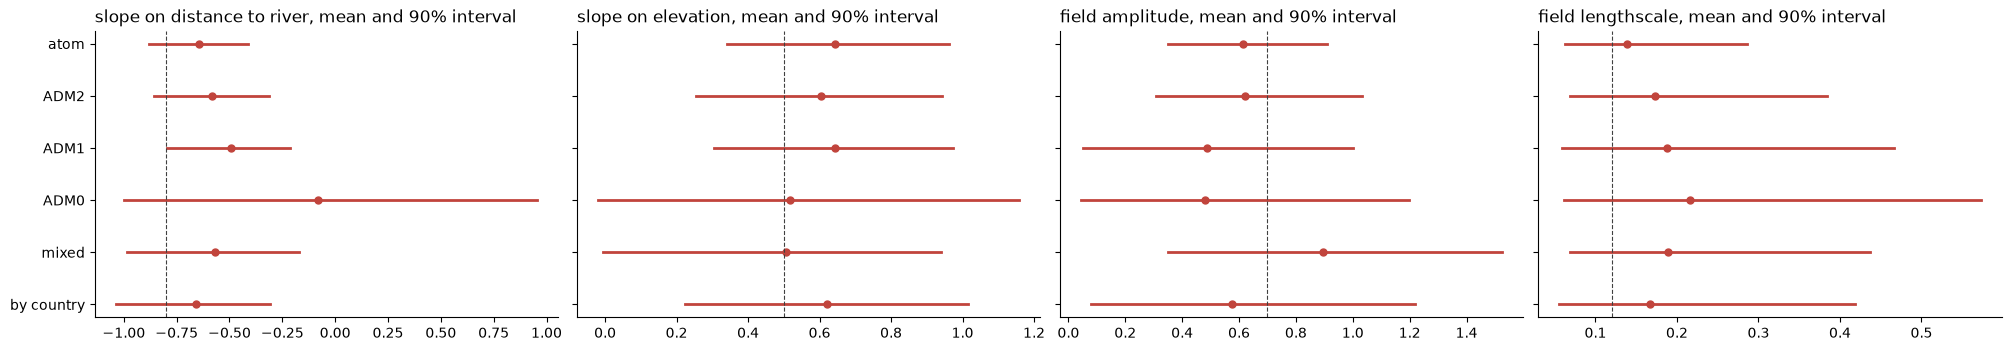

In [14]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)

TRUE_PARAMETERS = {
    **{f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)},
    "field amplitude": TRUE_FIELD_AMPLITUDE,
    "field lengthscale": TRUE_FIELD_LENGTHSCALE,
}


def parameter_draws(posterior):
    """Draws of every parameter with a known true value, keyed as in ``TRUE_PARAMETERS``."""
    return {
        **{f"slope on {name}": posterior["slopes"].sel(covariate=name) for name in COVARIATE_NAMES},
        "field amplitude": posterior["field_amplitude"],
        "field lengthscale": posterior["field_lengthscale"],
    }


figure, axes = plt.subplots(1,
                            len(TRUE_PARAMETERS),
                            figsize=(5.0 * len(TRUE_PARAMETERS), 3.4),
                            sharey=True)

for axis, (name, truth) in zip(axes, TRUE_PARAMETERS.items(), strict=True):
    for position, idata in enumerate(fits.values()):
        draws = parameter_draws(idata.posterior)[name]
        lower, upper = draws.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
        axis.plot([lower, upper],
                  [position, position],
                  color=POSTERIOR_COLOR,
                  linewidth=2.0)
        axis.plot(float(draws.mean()),
                  position,
                  "o",
                  color=POSTERIOR_COLOR,
                  markersize=5)
    axis.axvline(truth,
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=0.8)
    axis.set_title(f"{name}, mean and {INTERVAL:.0%} interval", loc="left")

axes[0].set_yticks(range(len(fits)), list(fits))
axes[0].invert_yaxis()
plt.show()

Every regime's 90% interval covers all four true values, with ADM1's river interval ending exactly at -0.8. The slopes are less precise than in 05 because the field absorbs part of the variation they would otherwise explain. ADM0 is again the widest by far, and its river slope sits near zero (-0.08). The field's hyperparameters are weakly identified by 163 events. Every posterior puts the lengthscale between 0.14 and 0.22 against a true 0.12, and the ADM1, ADM0 and per-country amplitude intervals run from near zero to 1 or above.

In [15]:
def atom_summary(idata):
    """How well the posterior over the field and the atom log rates matches the truth."""
    log_rate = idata.posterior["log_rate"]
    lower, upper = log_rate.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    error = log_rate.mean(dim=("chain", "draw")).to_numpy() - true_log_rate
    field_mean = idata.posterior["field"].mean(dim=("chain", "draw")).to_numpy()

    return {
        **{f"sd, {name}": float(draws.std()) for name, draws in parameter_draws(idata.posterior).items()},
        "field, correlation with truth": float(np.corrcoef(field_mean, true_field)[0, 1]),
        "atom log rate, rmse": float(np.sqrt((error**2).mean())),
        f"atom log rate, {INTERVAL:.0%} coverage": float(((true_log_rate >= lower) & (true_log_rate <= upper)).mean()),
        "atom log rate, interval width": float((upper - lower).mean()),
        "largest r_hat": float(
            az.summary(idata, var_names=["intercept", "slopes", "field_lengthscale", "field_amplitude"])["r_hat"].max()
        ),
        "divergences": int(idata.sample_stats["diverging"].sum()),
    }


pd.DataFrame({regime: atom_summary(idata) for regime, idata in fits.items()}).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"sd, slope on distance to river",0.14,0.16,0.18,0.60,0.25,0.22
"sd, slope on elevation",0.19,0.22,0.21,0.37,0.29,0.24
"sd, field amplitude",0.18,0.23,0.30,0.37,0.40,0.35
"sd, field lengthscale",0.08,0.11,0.20,0.24,0.13,0.16
"field, correlation with truth",0.56,0.54,0.29,0.27,0.56,0.43
"atom log rate, rmse",0.56,0.59,0.70,0.96,0.57,0.60
"atom log rate, 90% coverage",0.86,0.82,0.74,0.86,0.96,0.90
"atom log rate, interval width",1.54,1.50,1.55,2.65,2.16,1.90
largest r_hat,1.03,1.01,1.02,1.02,1.03,1.02
divergences,0.00,0.00,1.00,8.00,8.00,3.00


The field's correlation with the truth over the whole lattice is 0.56 for the oracle, 0.54 for ADM2, 0.56 for the mixed record and 0.43 for the per-country record, against 0.29 for ADM1 and 0.27 for ADM0. Coverage of the atom log rates runs from 74% (ADM1) to 96% (mixed). Every atom depends on the same few parameters and the same field, so coverage moves in blocks and one draw puts it above or below 90% by chance. ADM0's intervals are the widest (2.65 against 1.54 for the oracle). The ADM0 and mixed fits each have eight divergences, and every r_hat is at most 1.03.

### What the record shows against what the fit infers

The top row is the record as a reader without a model would map it: each event spread evenly over the unit it was reported in. A record reported at more than one level is drawn as a stack, one sheet per level over their sum, because spread onto a single sheet its levels blur together. The middle row is the posterior mean rate at each atom, and the bottom row is that mean against the truth. The first column is the truth itself: where the events actually fell, the rate they were drawn from, and the residual of the oracle fit. The top two rows share one log scale in events per atom.

In [16]:
def spread_at(counts, level):
    """The events reported at ``level``, each divided equally among the atoms of its unit."""
    return spread_over_units(counts[rows_of[level]], unit_of_atom[level])


def spread_evenly(counts):
    """Each reported event divided equally among the atoms of the unit it was reported in."""
    return sum(spread_at(counts, level) for level in ALL_LEVELS)


def record_layers(counts):
    """A record as one sheet per reporting level, coarsest first, then their sum."""
    layers = [
        (f"{level}, {counts[rows_of[level]].sum()} events", spread_at(counts, level), (level,))
        for level in reversed(LEVELS)
    ]

    return [*layers, ("sum", spread_evenly(counts), LEVELS)]


def posterior_rate(idata):
    """Posterior mean of the expected events at each atom."""
    return np.exp(idata.posterior["log_rate"]).mean(dim=("chain", "draw")).to_numpy()

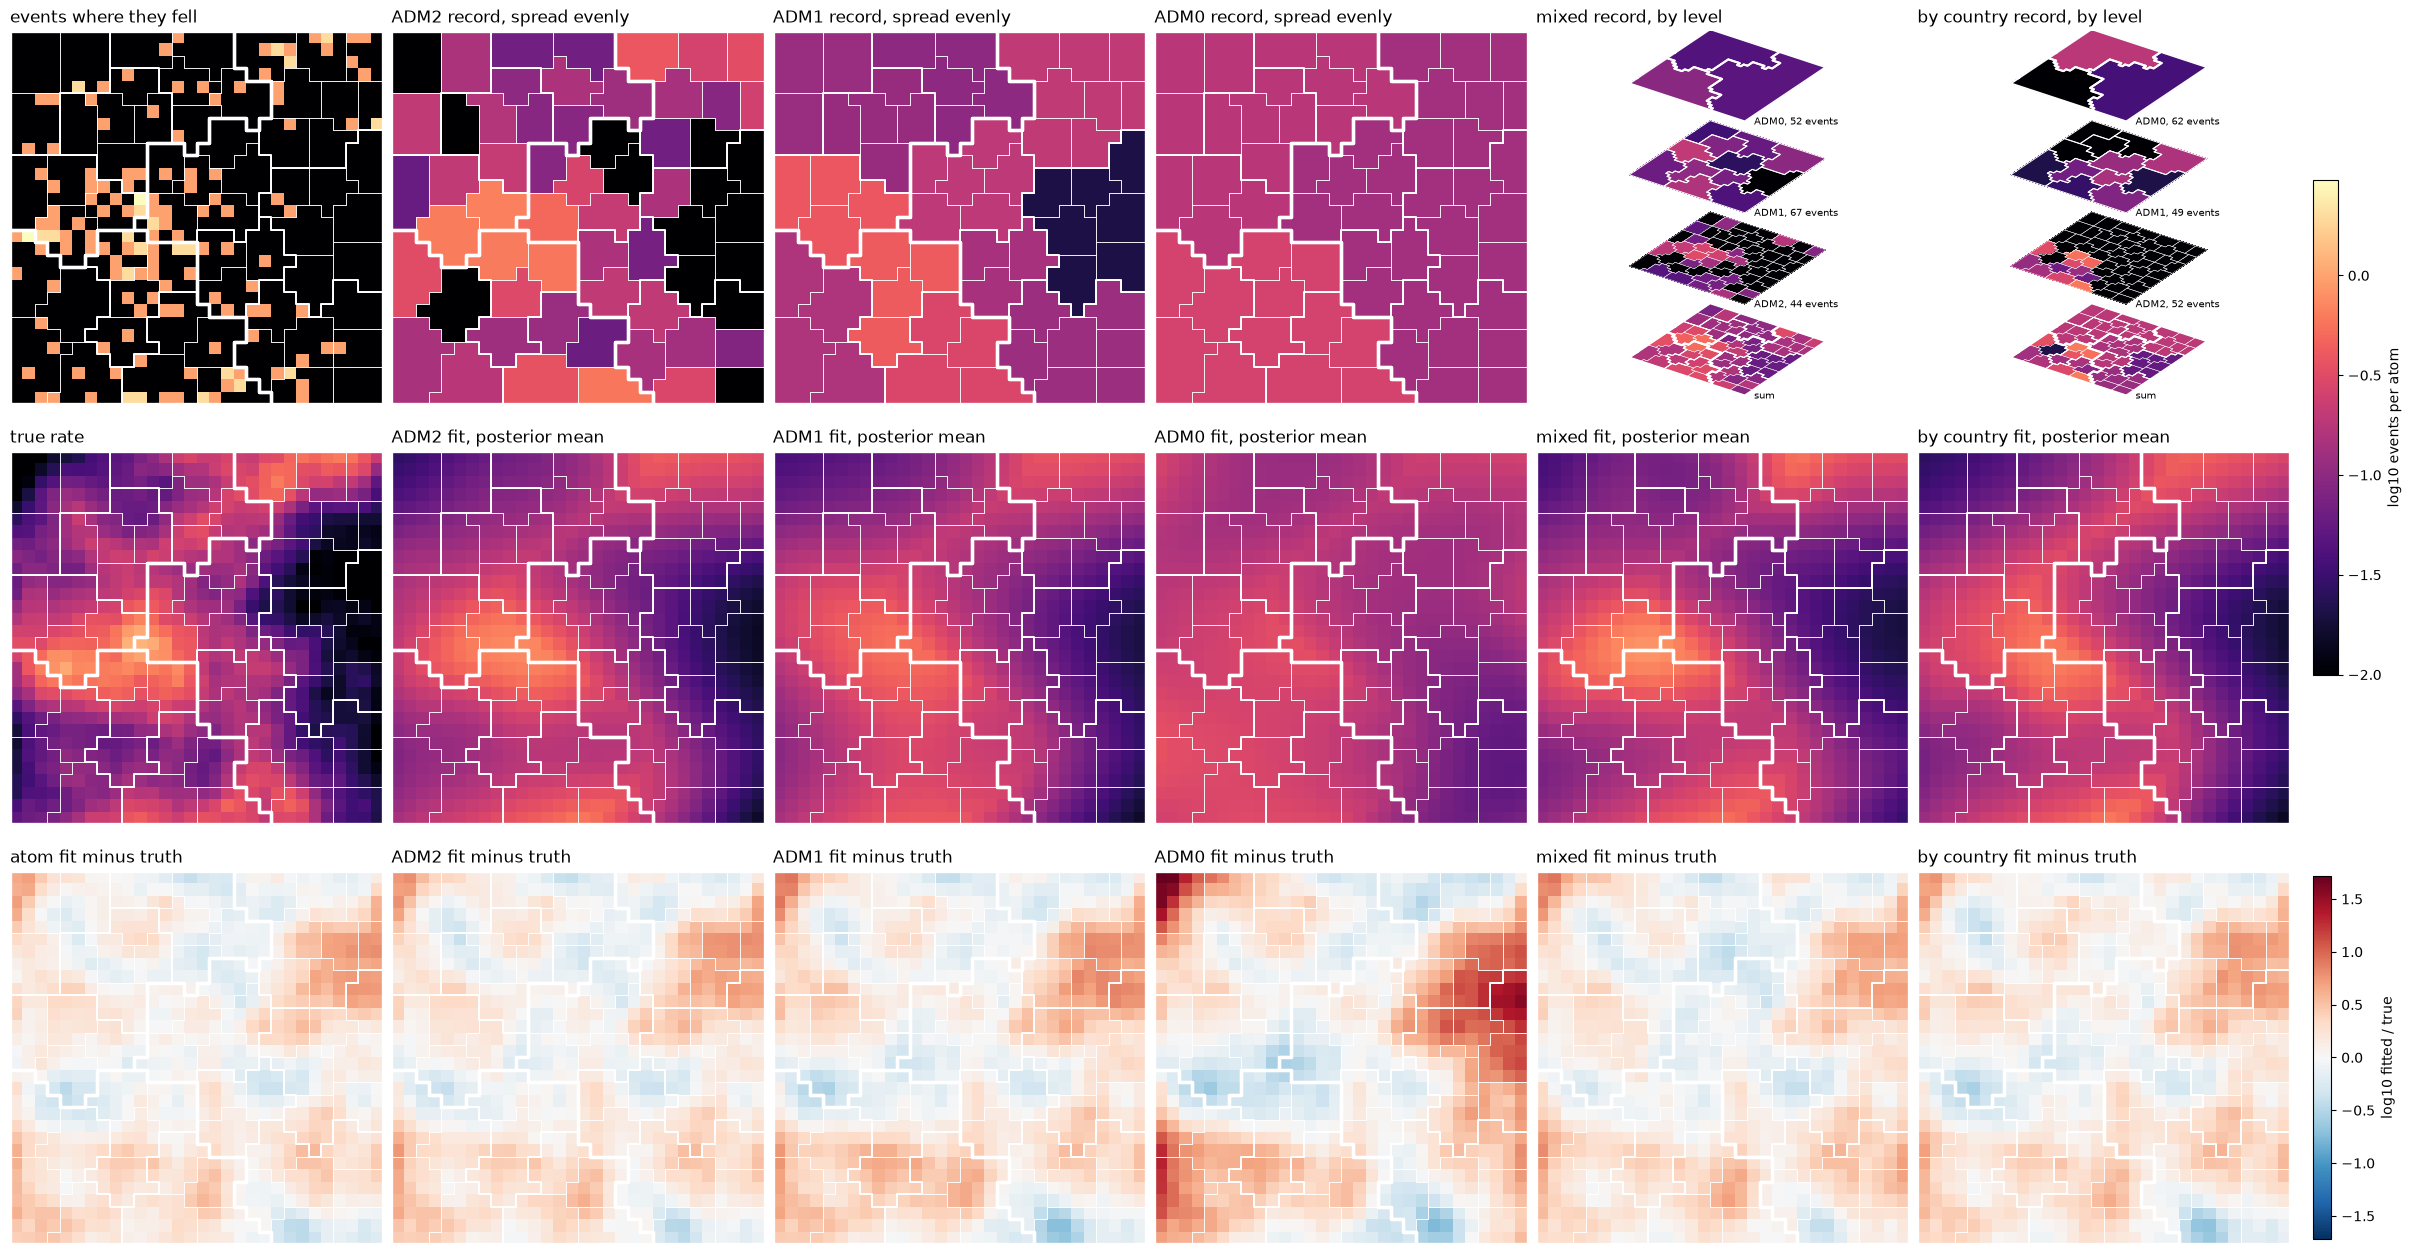

In [17]:
SHOWN_REGIMES = ("ADM2", "ADM1", "ADM0", "mixed", "by country")
STACKED_REGIMES = ("mixed", "by country")

columns = {"truth": (spread_evenly(regimes["atom"]), true_rate)}
columns |= {regime: (spread_evenly(regimes[regime]), posterior_rate(fits[regime])) for regime in SHOWN_REGIMES}

# The truth column has no fit of its own, so its residual is the oracle's: what the draw of events
# alone costs, before any reporting.
residuals = {
    name: np.log10(posterior_rate(fits["atom" if name == "truth" else name])) - np.log10(true_rate) for name in columns
}

low = np.log10(RATE_FLOOR)
high = np.log10(max(values.max() for pair in columns.values() for values in pair))
residual_limit = max(np.abs(residual).max() for residual in residuals.values())

figure, axes = plt.subplots(3, len(columns), figsize=(4.0 * len(columns), 12.6))
rate_axes = list(axes[:2].ravel())

for (name, (seen, inferred)), (top, middle, bottom) in zip(columns.items(), axes.T, strict=True):
    inferred_title = "true rate" if name == "truth" else f"{name} fit, posterior mean"
    residual_title = "atom fit minus truth" if name == "truth" else f"{name} fit minus truth"

    if name in STACKED_REGIMES:
        rate_axes.remove(top)
        top.remove()
        stack = figure.add_subplot(top.get_subplotspec(), projection="3d", proj_type="ortho")
        draw_stack(stack,
                   record_layers(regimes[name]),
                   borders,
                   vmin=low,
                   vmax=high,
                   label_size=7,
                   zoom=1.1,
                   line_scale=0.6)
        stack.set_title(f"{name} record, by level", loc="left")
    else:
        seen_title = "events where they fell" if name == "truth" else f"{name} record, spread evenly"
        plot_atoms(top,
                   floored_log10(seen),
                   borders,
                   title=seen_title,
                   vmin=low,
                   vmax=high)

    rate_drawn = plot_atoms(middle,
                            floored_log10(inferred),
                            borders,
                            title=inferred_title,
                            vmin=low,
                            vmax=high)
    residual_drawn = plot_atoms(bottom,
                                residuals[name],
                                borders,
                                title=residual_title,
                                cmap="RdBu_r",
                                vmin=-residual_limit,
                                vmax=residual_limit)

figure.colorbar(rate_drawn,
                ax=rate_axes,
                shrink=0.6,
                pad=0.01,
                label="log10 events per atom")
figure.colorbar(residual_drawn,
                ax=axes[2],
                shrink=0.9,
                pad=0.01,
                label="log10 fitted / true")
plt.show()

In [18]:
pd.DataFrame(
    {
        "rmse": {name: float(np.sqrt((residual**2).mean())) for name, residual in residuals.items()},
        "largest": {name: float(np.abs(residual).max()) for name, residual in residuals.items()},
    }
).rename(index={"truth": "atom"}).rename_axis("log10 residual").round(3)

,rmse,largest
log10 residual,,
atom,0.27,0.80
ADM2,0.28,0.82
ADM1,0.33,0.92
ADM0,0.50,1.72
mixed,0.29,0.92
by country,0.29,0.78


The ADM2 record already leaves many units empty, and the ADM0 record is three nearly flat blocks. The fits show where reporting runs out. ADM2, mixed and per-country rebuild the western hotspot and the empty east inside units, ADM1 keeps only the broad shape, and ADM0 is close to the covariate surface alone. The residual root mean square is 0.27 to 0.29 in log10 for the oracle, ADM2, mixed and per-country fits, 0.33 for ADM1 and 0.50 for ADM0, whose largest miss reaches 1.72, a factor of about 50.

### Each part of the log rate against the truth

The level, each covariate term and the field, posterior mean against the truth at every atom. The field is centered, since only its shape is identified apart from the intercept, and its mean is folded into the level.

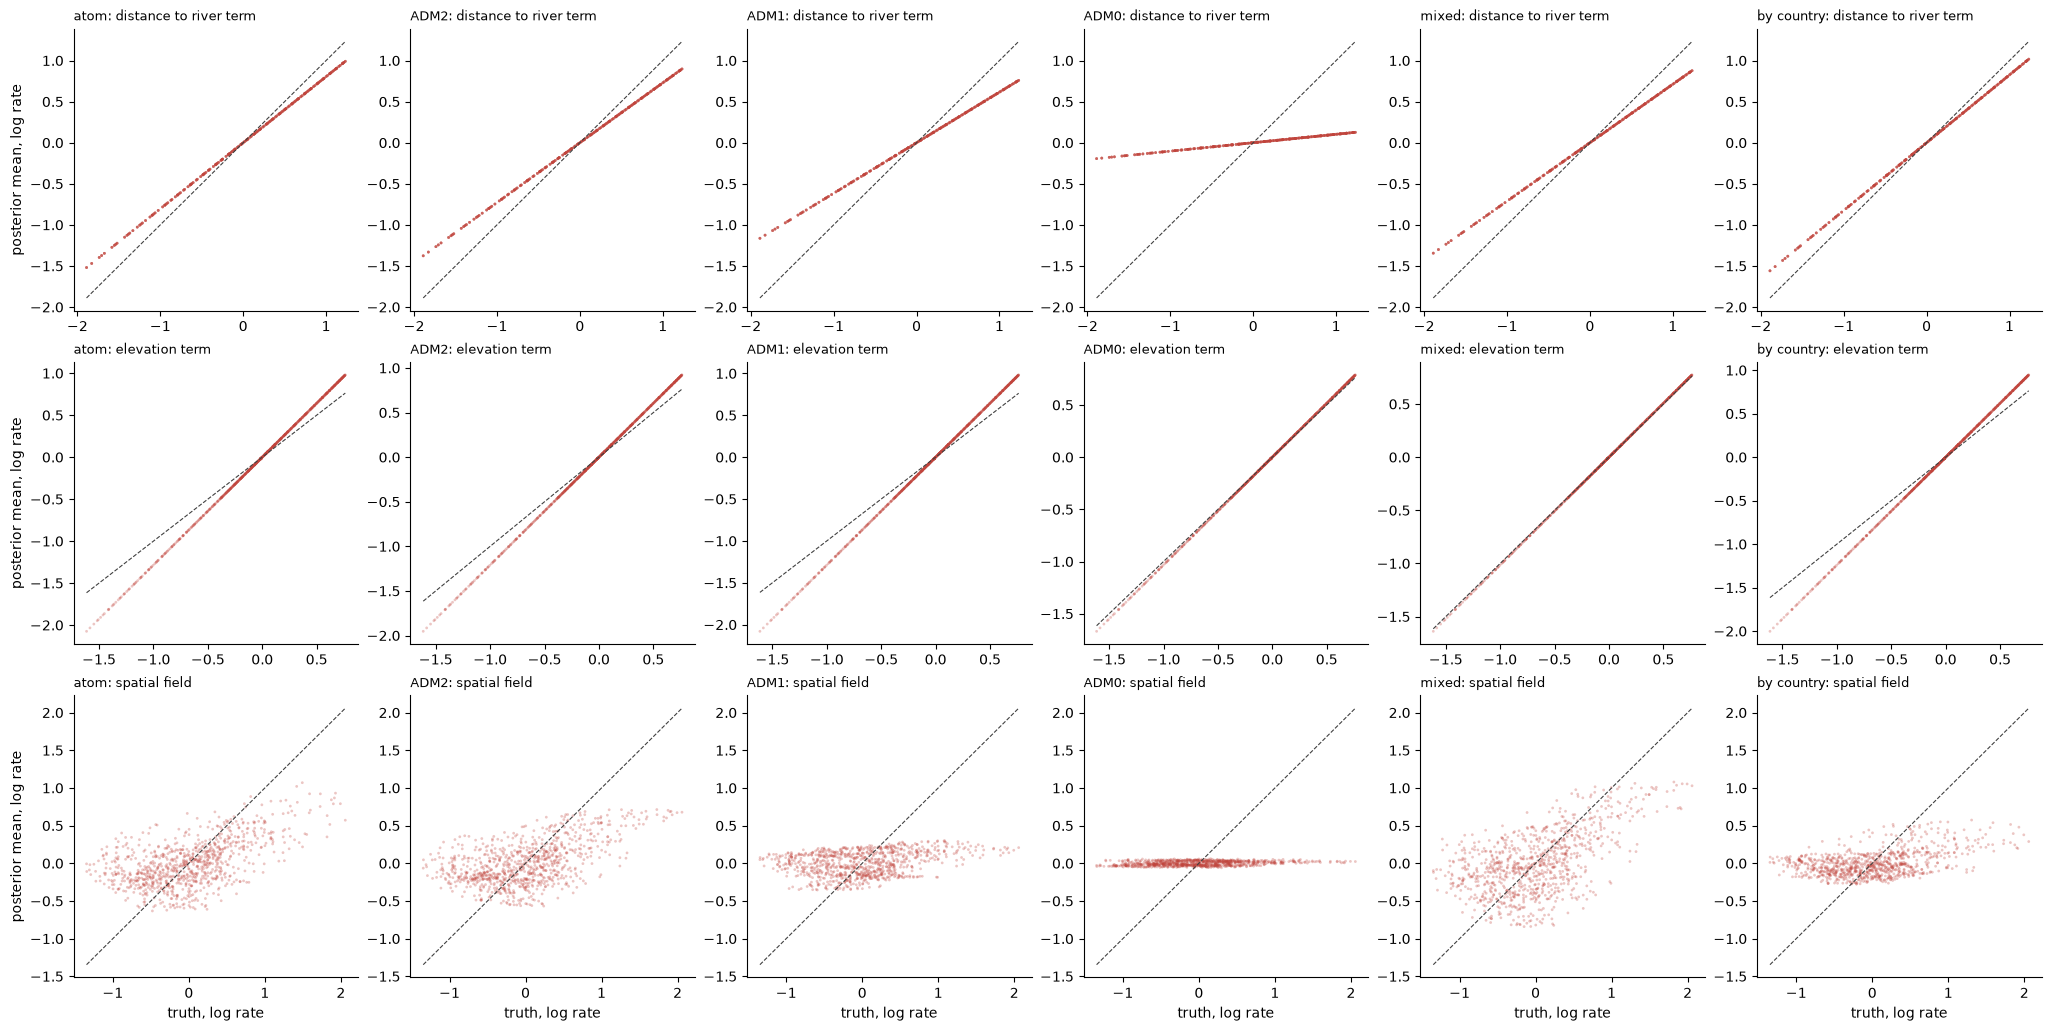

In [19]:
def covariate_terms_of(slopes):
    """Each covariate's contribution to the log rate at every atom."""
    return {
        f"{name} term": slope * values
        for name, slope, values in zip(COVARIATE_NAMES, slopes, covariates.T, strict=True)
    }


def components_of(posterior):
    """Posterior mean of each additive part of the log rate at every atom, the field centered into the level."""
    field_mean = posterior["field"].mean(dim="atom")

    return {
        "level": float((posterior["intercept"] + field_mean).mean()),
        **covariate_terms_of(posterior["slopes"].mean(dim=("chain", "draw")).to_numpy()),
        "spatial field": (posterior["field"] - field_mean).mean(dim=("chain", "draw")).to_numpy(),
    }


true_components = {"level": TRUE_INTERCEPT, **covariate_terms_of(TRUE_SLOPES), "spatial field": true_field}
fitted_components = {regime: components_of(idata.posterior) for regime, idata in fits.items()}
spatial_components = [name for name in true_components if name != "level"]

figure, axes = plt.subplots(len(spatial_components),
                            len(fits),
                            figsize=(3.4 * len(fits), 3.4 * len(spatial_components)))

for row, name in zip(axes, spatial_components, strict=True):
    truth = true_components[name]
    span = [truth.min(), truth.max()]
    for axis, (regime, fitted) in zip(row, fitted_components.items(), strict=True):
        axis.scatter(truth,
                     fitted[name],
                     s=4,
                     alpha=0.3,
                     color=POSTERIOR_COLOR,
                     edgecolor="none")
        axis.plot(span,
                  span,
                  color=TRUTH_COLOR,
                  linewidth=0.8,
                  linestyle="--")
        axis.set_title(f"{regime}: {name}", loc="left", fontsize=9)
    row[0].set_ylabel("posterior mean, log rate")

for axis in axes[-1]:
    axis.set_xlabel("truth, log rate")

plt.show()

In [20]:
pd.DataFrame(
    {
        regime: {
            "level, error": fitted["level"] - true_components["level"],
            **{
                f"{name}, rmse": float(np.sqrt(((fitted[name] - true_components[name]) ** 2).mean()))
                for name in spatial_components
            },
        }
        for regime, fitted in fitted_components.items()
    }
).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"level, error",0.18,0.21,0.26,0.25,0.11,0.17
"distance to river term, rmse",0.16,0.22,0.31,0.72,0.23,0.14
"elevation term, rmse",0.14,0.10,0.14,0.02,0.01,0.12
"spatial field, rmse",0.51,0.52,0.59,0.61,0.51,0.56


The field row carries the result. The oracle, ADM2 and mixed fits tilt along the diagonal, compressed toward zero. ADM1 collapses to a flat band, where the posterior mean has fallen back to the prior, ADM0 is flat at zero, and the per-country fit lies between. The covariate terms remain straight lines. ADM0's river term is nearly flat, the slope near zero from the forest plot, and every other fit's river term is shallower than the truth. The elevation terms are close to the truth or slightly steep in every regime, including the oracle.

### The fitted field as a map

The true field beside each regime's posterior-mean field, on one color scale. Each fitted field is centered, since the intercept absorbs its mean.

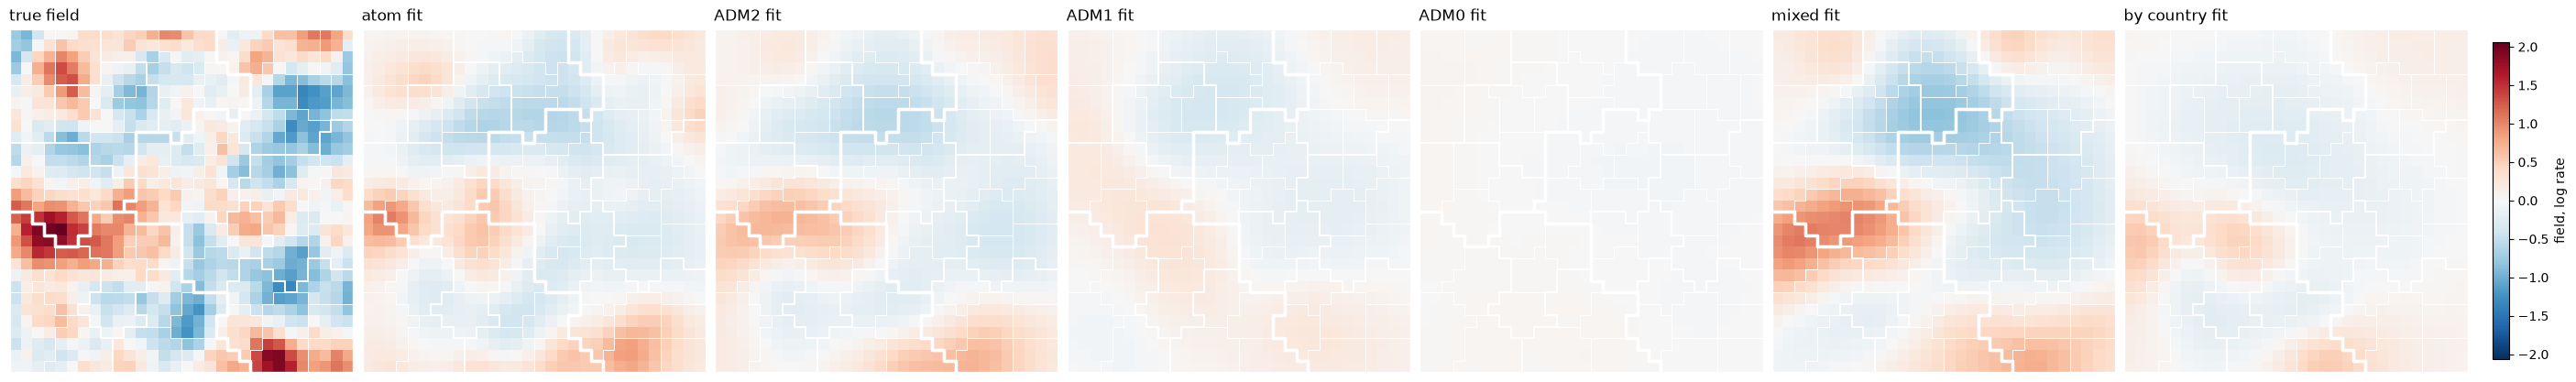

In [26]:
fitted_fields = {regime: idata.posterior["field"].mean(dim=("chain", "draw")).to_numpy() for regime, idata in fits.items()}

plot_fields({"true field": true_field} | {f"{regime} fit": field - field.mean() for regime, field in fitted_fields.items()},
            borders)
plt.show()

The oracle, ADM2 and mixed fits find the same three features: the western hotspot, the southern one, and the cold band across the north. Each is a smoothed, paler version of the truth, and none resolves the small patches at the scale of an ADM2 unit. The ADM1 fit keeps a faint trace of the western hotspot, the per-country fit a fainter one, and the ADM0 fit is flat.

### Where the covariates and the field overlap

Each covariate's correlation with the true field, over atoms, between the means of units at each level, and within units at each level.

In [21]:
def unit_mean_at_atoms(values, units):
    """Each atom's value replaced by the mean over the unit it sits in."""
    return (np.bincount(units, weights=values) / np.bincount(units))[units]


def correlation(left, right):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(left, right)[0, 1])


# A report at a level sees only between-unit contrasts, so a covariate that tracks the field across
# units at that level can take credit for it once the field itself is not resolved.
field_split = {level: unit_mean_at_atoms(true_field, unit_of_atom[level]) for level in LEVELS}

pd.DataFrame(
    {
        name: {
            "atoms": correlation(true_field, values),
            **{
                f"between {level} units": correlation(field_split[level], unit_mean_at_atoms(values, unit_of_atom[level]))
                for level in LEVELS
            },
            **{
                f"within {level} units": correlation(true_field - field_split[level],
                                                     values - unit_mean_at_atoms(values, unit_of_atom[level]))
                for level in LEVELS
            },
        }
        for name, values in zip(COVARIATE_NAMES, covariates.T, strict=True)
    }
).rename_axis("correlation with the true field").round(3)

,distance to river,elevation
correlation with the true field,,
atoms,0.04,0.16
between ADM2 units,0.06,0.18
between ADM1 units,0.22,0.42
between ADM0 units,0.41,0.93
within ADM2 units,-0.02,0.09
within ADM1 units,-0.04,0.01
within ADM0 units,0.03,0.05


Elevation tracks the field between coarse units, 0.42 across ADM1 means and 0.93 across the three countries, but not inside them, where every correlation is below 0.1. A record that cannot resolve the field could let the elevation slope take up the part of the field that runs with elevation. This draw shows no sign of it: the ADM1 fit's elevation slope (0.64) equals the oracle's, and the ADM0 fit's (0.52) is close to the truth. The 0.93 rests on three points, and the bias it allows is smaller than the spread between draws of the events.

### Field recovery inside units

The fitted field against the truth after removing each unit's own mean, so only structure below the unit counts. Rows split by the level of the unit and by country, each country labeled by how it reports in the per-country regime.

In [22]:
INSIDE_LEVELS = ("ADM2", "ADM1")

country_of_atom = unit_of_atom["ADM0"]
habits = [", ".join(f"{level} {share:.0%}" for level, share in shares.items()) for shares in COUNTRY_SHARES]
field_means = {regime: idata.posterior["field"].mean(dim=("chain", "draw")).to_numpy() for regime, idata in fits.items()}


def inside_recovery(field_mean, level, atoms):
    """Correlation of the fitted field with the truth after removing each unit's mean, over ``atoms``."""
    fitted = field_mean - unit_mean_at_atoms(field_mean, unit_of_atom[level])
    truth = true_field - unit_mean_at_atoms(true_field, unit_of_atom[level])

    return correlation(fitted[atoms], truth[atoms])


groups = {"all countries": np.ones(n_atoms, dtype=bool)}
groups |= {f"ADM0 {country} ({habit})": country_of_atom == country for country, habit in enumerate(habits)}

pd.DataFrame(
    {
        regime: {
            (f"inside {level} units", group): inside_recovery(field_mean, level, atoms)
            for level in INSIDE_LEVELS
            for group, atoms in groups.items()
        }
        for regime, field_mean in field_means.items()
    }
).rename_axis(["field, correlation with truth", "over"]).round(3)

atom  ADM2  ADM1  \
field, correlation with truth over                                            
inside ADM2 units             all countries                0.51  0.37  0.19   
                              ADM0 0 (ADM2 80%, ADM1 20%)  0.53  0.44  0.34   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.37  0.23  0.12   
                              ADM0 2 (ADM0 100%)           0.62  0.47  0.17   
inside ADM1 units             all countries                0.58  0.57  0.31   
                              ADM0 0 (ADM2 80%, ADM1 20%)  0.66  0.70  0.53   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.46  0.47  0.27   
                              ADM0 2 (ADM0 100%)           0.71  0.64  0.24   

                                                           ADM0  mixed  \
field, correlation with truth over                                       
inside ADM2 units             all countries                0.10   0.41   
                              ADM0 0 (ADM2 80%, ADM1 20%) -0.13   0.45   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.17   0.30   
                              ADM0 2 (ADM0 100%)           0.20   0.48   
inside ADM1 units             all countries                0.20   0.61   
                              ADM0 0 (ADM2 80%, ADM1 20%) -0.26   0.71   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.39   0.53   
                              ADM0 2 (ADM0 100%)           0.18   0.66   

                                                           by country  
field, correlation with truth over                                     
inside ADM2 units             all countries                      0.26  
                              ADM0 0 (ADM2 80%, ADM1 20%)        0.31  
                              ADM0 1 (ADM1 80%, ADM0 20%)        0.14  
                              ADM0 2 (ADM0 100%)                 0.38  
inside ADM1 units             all countries                      0.47  
                              ADM0 0 (ADM2 80%, ADM1 20%)        0.63  
                              ADM0 1 (ADM1 80%, ADM0 20%)        0.41  
                              ADM0 2 (ADM0 100%)                 0.56

Inside units the ranking holds. Over all countries and inside ADM1 units, the oracle, ADM2 and mixed fits reach 0.57 to 0.61, the per-country fit 0.47, ADM1 0.31 and ADM0 0.20. Inside ADM2 units every regime drops, the oracle to 0.51 and ADM2 to 0.37.

ADM2 reports carry no information about where an event fell inside its ADM2 unit, yet the ADM2 fit recovers 0.37 of the field there. The smooth field fitted to neighboring unit totals places gradients inside each unit, and those gradients point the right way often enough to correlate with the truth.

The ADM0-only country is the case the per-country regime exists for. There the per-country fit reaches 0.38 inside ADM2 units and 0.56 inside ADM1 units, against 0.20 and 0.18 when every country reports at ADM0, although the country contributes one number in both records. Any gain has to come from its neighbors' finer reports, through the shared slopes, the shared field hyperparameters and the field's continuity across the border. The noise floor is wide, though. The all-ADM0 fit has no information inside any country, and its correlations inside ADM1 units range from -0.26 to 0.39 across the three. The country's 0.56 sits above that range but not far above it, so the borrowing is suggestive and needs replicate draws to establish.

## What this establishes

With a spatial field the covariates do not explain, the resolution of the report sets how much of the field is recoverable, and the inside-unit variance table predicts the order. ADM2 reports recover the field nearly as well as exact locations (correlation 0.54 against 0.56), ADM1 reports reach 0.29 and ADM0 reports 0.27. A record mixing levels recovers as much as its ADM2 share carries. The same order holds inside ADM1 and ADM2 units, where the smooth field lets even unit totals place some structure below the unit. An ADM0-only country may borrow from better-reported neighbors, but one draw cannot separate that from noise.

The posteriors stay honest. Every interval covers the true slopes and field hyperparameters, and the intervals widen where reports thin out. With 163 events the field's hyperparameters are weakly identified even from exact locations. A correlation computed inside one country swings over a range of about 0.6 with no information behind it, so country-level comparisons need replicate draws of events and field. Notebook 07 adds partial pooling to capture effects inside units.